# 03 — Planning read-outs and a 2027 outlook

**Kok Zhailau ski terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

This notebook joins the terrain layers from notebook 01 to the snow record from
notebook 02 and turns them into three things a planner can act on: where exposure
actually changes snow behaviour, where to send a field team, and what the coming
spring could look like under shifted timing.

**Framing.** This is an independent study on open data. It is not commissioned by
or endorsed by any resort operator or design office. The official statement of
18 November 2026 on the Almaty SuperSki cluster names no individual resort site,
so this rectangle is the author's own study area, not a project boundary.

In [1]:
import os
os.environ["KZ_AREA"] = "superski"   # the current study area, derived from the
#                                      operator's general plan - see notebook 06

import json
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from config import (ELEV_BAND_M, FOCUS_BAND, MIN_SEASONS_MULTIYEAR, MIN_VALID_OBS,
                    OUT_TAB, OUT_TIF, OUTLOOK_MONTHS_2027, OUTLOOK_YEAR, SEASONS,
                    SKIABLE_SLOPE_MAX, SKIABLE_SLOPE_MIN, SPRING_SHIFT_DAYS,
                    SPRING_WINDOW, STEEP_SLOPE_MIN)
from dem import write_geotiff
from grids import DEM_GRID, S2_GRID
from pipeline_snow import historical_days, load_days
from pipeline_terrain import all_insolation, terrain
from planning import (aspect_insolation_table, band_insolation_contrast,
                      field_priority, skiable_mask, steep_layer)
from snow import select_days, snow_frequency
from stack import build
from viz import PRIORITY_CMAP, PRIORITY_LABELS, PRIORITY_NORM, map_panel, save

pd.set_option("display.width", 170)
RUN_DATE = date.today().isoformat()

t = terrain()
ins = all_insolation(t)
st = build(t, ins)
days, manifest, _ = load_days(verbose=False)
hist = historical_days(days)

dem, slope, aspect = st["dem"], st["slope"], st["aspect"]
ski = skiable_mask(slope)
print(f"run date: {RUN_DATE}")
print(f"analysis stack on the 20 m Sentinel-2 grid: {S2_GRID.shape}")
print(f"terrain resampled from the 30 m DEM grid (aspect as a unit vector)")
print(f"slopes {SKIABLE_SLOPE_MIN:.0f}–{SKIABLE_SLOPE_MAX:.0f}°: "
      f"{ski.sum()*400/1e6:.2f} km² of {S2_GRID.area_km2:.1f} km² "
      f"({ski.mean()*100:.0f}%)")

run date: 2026-11-24
analysis stack on the 20 m Sentinel-2 grid: (400, 437)
terrain resampled from the 30 m DEM grid (aspect as a unit vector)
slopes 15–35°: 46.29 km² of 69.9 km² (66%)


## 1. Does exposure change snow behaviour?

The test holds elevation fixed. Inside each 100 m band, on 15–35° slopes only,
pixels are split by their own band's lowest and highest insolation quartile, and
the snow detection frequency of the two groups is compared. Any difference left is
an exposure effect, not an elevation effect.

Two periods are reported: the four-season spring window (the robust number) and
March–April 2023 alone (comparable to the earlier pilot run).

In [2]:
spring4 = snow_frequency(select_days(hist, month_day_window=SPRING_WINDOW),
                         min_valid=MIN_VALID_OBS, min_seasons=MIN_SEASONS_MULTIYEAR)
marapr23 = snow_frequency(select_days(hist, start="2023-03-01", end="2023-04-30"),
                          min_valid=MIN_VALID_OBS)
print(f"spring window {SPRING_WINDOW[0]}→{SPRING_WINDOW[1]}, 4 seasons: "
      f"{spring4['n_dates']} dates, coverage {spring4['coverage']*100:.1f}%")
print(f"March–April 2023: {marapr23['n_dates']} dates, coverage {marapr23['coverage']*100:.1f}%")

contrast4 = band_insolation_contrast(dem, slope, st["insol_mar_apr"], spring4["frequency"])
contrast23 = band_insolation_contrast(dem, slope, st["insol_mar_apr"], marapr23["frequency"])
contrast4.to_csv(OUT_TAB / "exposure_contrast_spring_4season.csv", index=False)
contrast23.to_csv(OUT_TAB / "exposure_contrast_mar_apr_2023.csv", index=False)

cols = ["band_label", "n_pixels_skiable", "n_low_insol", "n_high_insol",
        "coverage_low", "coverage_high", "median_snow_freq_low",
        "median_snow_freq_high", "snow_freq_difference"]
print("\nFour-season spring window — lowest vs highest insolation quartile, 15–35° slopes")
print(contrast4[cols].to_string(index=False))

spring window 03-11→04-20, 4 seasons: 31 dates, coverage 97.4%
March–April 2023: 13 dates, coverage 86.1%

Four-season spring window — lowest vs highest insolation quartile, 15–35° slopes
band_label  n_pixels_skiable  n_low_insol  n_high_insol  coverage_low  coverage_high  median_snow_freq_low  median_snow_freq_high  snow_freq_difference
 1400-1500               653          164           164         1.000          1.000                 0.556                  0.050                 0.506
 1500-1600              2946          737           737         0.863          1.000                 0.476                  0.050                 0.426
 1600-1700              3450          863           863         0.855          0.995                 0.250                  0.167                 0.083
 1700-1800              5793         1449          1449         0.965          1.000                 0.500                  0.175                 0.325
 1800-1900              7657         1915          1

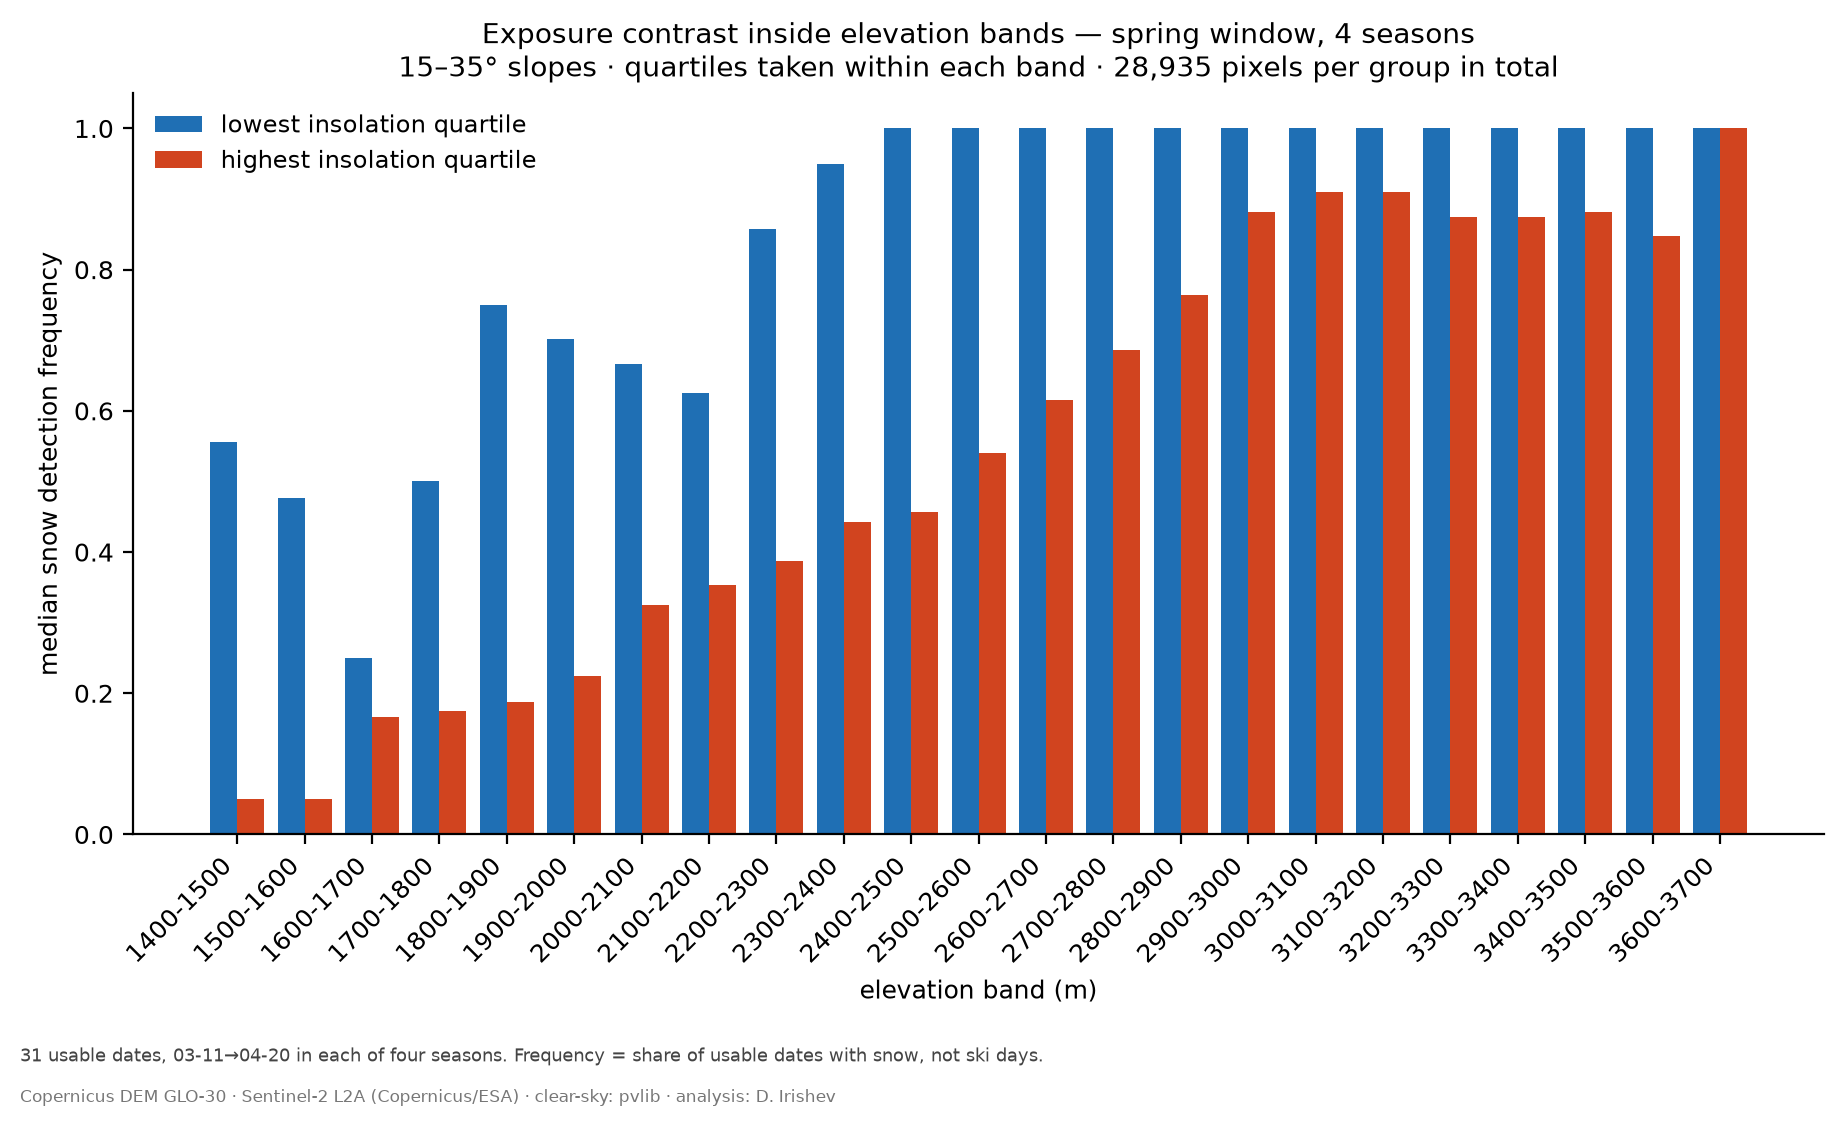

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/03_exposure_contrast_by_band.png')

In [3]:
fig, ax = plt.subplots(figsize=(9.2, 5.2))
x = np.arange(len(contrast4))
ax.bar(x - 0.2, contrast4["median_snow_freq_low"], 0.4, label="lowest insolation quartile",
       color="#1f6fb4")
ax.bar(x + 0.2, contrast4["median_snow_freq_high"], 0.4, label="highest insolation quartile",
       color="#d1441f")
ax.set_xticks(x)
ax.set_xticklabels(contrast4["band_label"], rotation=45, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("median snow detection frequency")
ax.set_xlabel("elevation band (m)")
ax.set_title("Exposure contrast inside elevation bands — spring window, 4 seasons\n"
             f"15–35° slopes · quartiles taken within each band · "
             f"{int(contrast4['n_low_insol'].sum()):,} pixels per group in total")
ax.legend(frameon=True, framealpha=0.92, edgecolor="none", loc="upper left", fontsize=8.5)
fig.tight_layout()
save(fig, "03_exposure_contrast_by_band.png",
     f"{spring4['n_dates']} usable dates, {SPRING_WINDOW[0]}→{SPRING_WINDOW[1]} in each of "
     f"four seasons. Frequency = share of usable dates with snow, not ski days.")

### The headline band, 2200–2300 m

In [4]:
row4 = contrast4[contrast4.elev_band_m == FOCUS_BAND[0]].iloc[0]
row23 = contrast23[contrast23.elev_band_m == FOCUS_BAND[0]].iloc[0]
summary = pd.DataFrame([
    {"period": f"spring window {SPRING_WINDOW[0]}→{SPRING_WINDOW[1]}, 4 seasons",
     "n_dates": spring4["n_dates"], **{k: row4[k] for k in cols[1:]}},
    {"period": "March–April 2023 only", "n_dates": marapr23["n_dates"],
     **{k: row23[k] for k in cols[1:]}},
])
summary.to_csv(OUT_TAB / "focus_band_2200_2300_summary.csv", index=False)
print(summary.to_string(index=False))

aspect_tbl = aspect_insolation_table(dem, slope, aspect, st["insol_mar_apr"],
                                     spring4["frequency"], FOCUS_BAND)
aspect_tbl.to_csv(OUT_TAB / "focus_band_aspect_summary.csv", index=False)
print("\nNorth vs south sector in the same band (four-season spring window):")
print(aspect_tbl.to_string(index=False))

                              period  n_dates  n_pixels_skiable  n_low_insol  n_high_insol  coverage_low  coverage_high  median_snow_freq_low  median_snow_freq_high  snow_freq_difference
spring window 03-11→04-20, 4 seasons       31              7381         1846          1846         0.969            1.0                 0.857                  0.387                  0.47
               March–April 2023 only       13              7381         1846          1846         0.803            1.0                 0.750                  0.100                  0.65

North vs south sector in the same band (four-season spring window):
  aspect_sector  n_pixels  area_km2  median_insolation_kwh_m2  coverage  median_snow_freq
 north (315-45)      2812    1.1248                     263.2     0.978             0.875
south (135-225)      1125    0.4500                     528.8     1.000             0.325
      east/west      3444    1.3776                     406.9     0.991             0.708


### Comparison with the earlier pilot run

The pilot reported, for March–April 2023: 12 candidate dates, ~74% coverage at
≥4 usable observations, and in the 2200–2300 m band a median snow frequency of
~94% in the lowest insolation quartile against ~23% in the highest.

In [5]:
pilot = pd.DataFrame([
    {"quantity": "area of the study rectangle (km²)", "pilot": "69.1",
     "this_run": f"{DEM_GRID.area_km2:.2f}",
     "agrees": ("yes" if abs(DEM_GRID.area_km2 - 69.1) < 0.5
                else "no - the study area moved, see notebook 06")},
    {"quantity": "candidate dates, Mar–Apr 2023", "pilot": "12",
     "this_run": f"{marapr23['n_dates']}", "agrees": "within one date"},
    {"quantity": "coverage at ≥4 usable obs, Mar–Apr 2023", "pilot": "~74%",
     "this_run": f"{marapr23['coverage']*100:.0f}%", "agrees": "higher here"},
    {"quantity": "2200–2300 m, low-insolation quartile", "pilot": "~94%",
     "this_run": f"{row23['median_snow_freq_low']*100:.0f}%", "agrees": "lower here"},
    {"quantity": "2200–2300 m, high-insolation quartile", "pilot": "~23%",
     "this_run": f"{row23['median_snow_freq_high']*100:.0f}%", "agrees": "close"},
    {"quantity": "seasons processed", "pilot": "1 of 4 complete (41 of 112 scenes cached)",
     "this_run": f"4 of 4 complete ({len(manifest)-1} historical scenes)", "agrees": "improved"},
])
pilot.to_csv(OUT_TAB / "pilot_comparison.csv", index=False)
print(pilot.to_string(index=False))
print(f"""
Reading of the differences, in order of likely size:

1. The pilot ran on the original 69.1 km² rectangle; this run covers
   {DEM_GRID.area_km2:.2f} km². Where those differ, the rows below are comparing two
   areas, not two methods — notebook 06 section 1 explains why the area moved.
2. Coverage is {marapr23['coverage']*100:.0f}% here against ~74%. This run keeps a pixel whenever the
   SCL class permits a snow / no-snow decision; a stricter earlier mask would have
   dropped marginal pixels, and those sit mostly on shaded slopes.
3. That is also the most likely reason the low-insolation group reads
   {row23['median_snow_freq_low']*100:.0f}% rather than ~94%: the extra pixels recovered in the low quartile
   are the hard ones — deep shade, where NDSI is weakest and a snow-covered pixel is
   most likely to be scored snow-free. Coverage in the low quartile is
   {row23['coverage_low']*100:.0f}% against {row23['coverage_high']*100:.0f}% in the high quartile, so the
   groups are not equally observed.
4. The high-insolation group agrees closely ({row23['median_snow_freq_high']*100:.0f}% vs ~23%), which is what
   one expects if the disagreement is a shade-detection effect rather than a
   difference in the snow rule itself.

The direction and the order of magnitude reproduce; the contrast is smaller here.
Resolving it needs ground truth, not more processing — which is the point of the
field pilot below.""")

                               quantity                                     pilot                                this_run                                     agrees
      area of the study rectangle (km²)                                      69.1                                   70.17 no - the study area moved, see notebook 06
          candidate dates, Mar–Apr 2023                                        12                                      13                            within one date
coverage at ≥4 usable obs, Mar–Apr 2023                                      ~74%                                     86%                                higher here
   2200–2300 m, low-insolation quartile                                      ~94%                                     75%                                 lower here
  2200–2300 m, high-insolation quartile                                      ~23%                                     10%                                      close
          

## 2. Where to send a field team

Two end-members are worth measuring, because they are where the model is most
exposed: shaded terrain the satellite calls reliably snowy, and sunny terrain it
calls unreliable. A pair of plots on opposite exposures inside one elevation band
is the cheapest test that can falsify the map.

In [6]:
prio, prio_meta = field_priority(spring4["frequency"], st["insol_mar_apr"], slope)
steep, steep_meta = steep_layer(slope, STEEP_SLOPE_MIN)
print(json.dumps(prio_meta, indent=1))
print(json.dumps(steep_meta, indent=1))

prio_tbl = pd.DataFrame([
    {"class": c, "label": prio_meta["labels"][c],
     "pixels": prio_meta["class_counts"][c],
     "area_km2": prio_meta["class_area_km2"][c]}
    for c in range(5)])
prio_tbl.to_csv(OUT_TAB / "field_priority_classes.csv", index=False)
print("\n" + prio_tbl.to_string(index=False))

{
 "insol_low_cut_kwh_m2": 285.7,
 "insol_high_cut_kwh_m2": 464.7,
 "freq_high_threshold": 0.75,
 "freq_low_threshold": 0.4,
 "slope_window_deg": [
  15.0,
  35.0
 ],
 "skiable_area_km2": 46.286,
 "labels": {
  "0": "outside the 15-35 deg slope window",
  "1": "low exposure and frequent snow",
  "2": "high exposure and infrequent snow",
  "3": "other skiable terrain",
  "4": "skiable, insufficient observation coverage"
 },
 "class_counts": {
  "0": 59084,
  "1": 18401,
  "2": 11045,
  "3": 84543,
  "4": 1727
 },
 "class_area_km2": {
  "0": 23.634,
  "1": 7.36,
  "2": 4.418,
  "3": 33.817,
  "4": 0.691
 }
}
{
 "threshold_deg": 30.0,
 "n_pixels": 94654,
 "area_km2": 37.862,
 "note": "Geometry only. Avalanche terrain classification needs snowpack, wind transport, start/runout zones and local expertise."
}

 class                                      label  pixels  area_km2
     0         outside the 15-35 deg slope window   59084    23.634
     1             low exposure and frequent snow

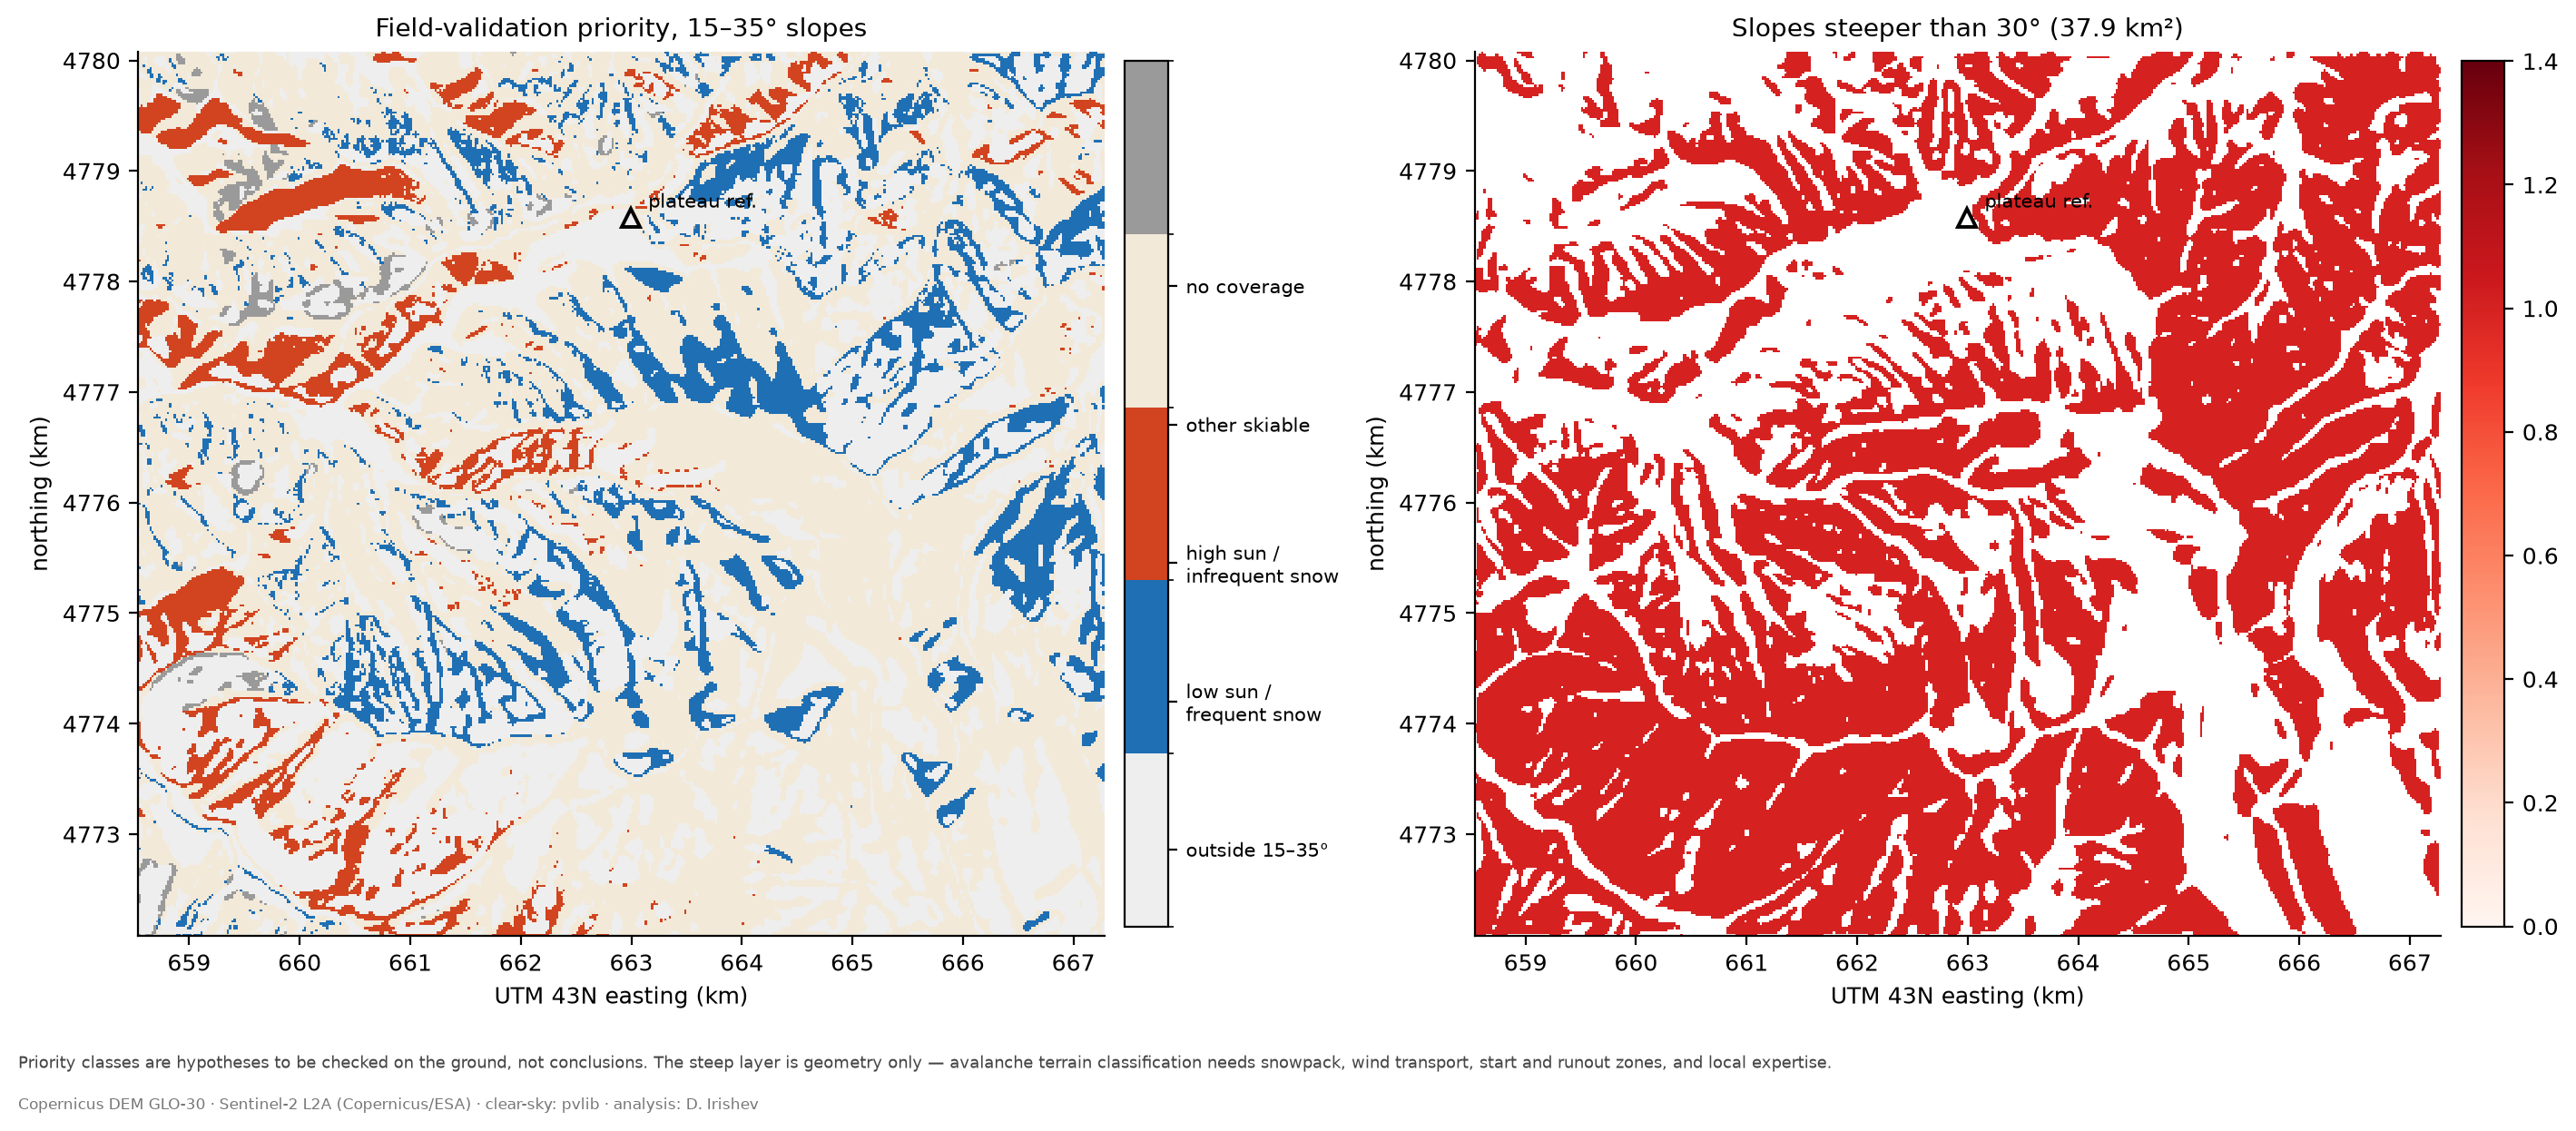

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/03_field_priority_and_steep.png')

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.8))
map_panel(axes[0], prio.astype("float32"), S2_GRID, PRIORITY_CMAP,
          norm=PRIORITY_NORM, title="Field-validation priority, 15–35° slopes",
          cbar_label="", shade=0, discrete_labels=PRIORITY_LABELS)
map_panel(axes[1], np.where(steep > 0, 1.0, np.nan), S2_GRID, "Reds", 0, 1.4,
          title=f"Slopes steeper than {STEEP_SLOPE_MIN:.0f}° "
                f"({steep_meta['area_km2']:.1f} km²)",
          cbar_label="", shade=0, dem=dem)
fig.tight_layout()
save(fig, "03_field_priority_and_steep.png",
     "Priority classes are hypotheses to be checked on the ground, not conclusions. "
     "The steep layer is geometry only — avalanche terrain classification needs "
     "snowpack, wind transport, start and runout zones, and local expertise.")

## 3. Clear-sky insolation for 2027

Solar geometry for 2027 is deterministic; only the atmosphere is climatological.
These are clear-sky ceilings, not expected irradiance — real cloud will reduce
them, and the reduction is itself an unmeasured local quantity here.

In [8]:
import calendar

rows = []
north = (aspect >= 315) | (aspect < 45)
south = (aspect >= 135) & (aspect < 225)
band = (dem >= FOCUS_BAND[0]) & (dem < FOCUS_BAND[1]) & ski
for m in OUTLOOK_MONTHS_2027:
    key = f"{OUTLOOK_YEAR}_{m:02d}"
    a = st[f"insol_{key}"]
    rows.append({
        "month": f"{OUTLOOK_YEAR}-{m:02d}",
        "month_name": calendar.month_name[m],
        "days": calendar.monthrange(OUTLOOK_YEAR, m)[1],
        "median_all_terrain_kwh_m2": round(float(np.nanmedian(a)), 1),
        "median_north_2200_2300": round(float(np.nanmedian(a[band & north])), 1),
        "median_south_2200_2300": round(float(np.nanmedian(a[band & south])), 1),
        "south_minus_north": round(float(np.nanmedian(a[band & south])
                                         - np.nanmedian(a[band & north])), 1),
        "south_over_north_ratio": round(float(np.nanmedian(a[band & south])
                                              / np.nanmedian(a[band & north])), 2),
    })
outlook = pd.DataFrame(rows)
outlook.to_csv(OUT_TAB / "insolation_2027_monthly.csv", index=False)
print(f"n pixels: north {int((band & north).sum())}, south {int((band & south).sum())} "
      f"(15–35° slopes, {int(FOCUS_BAND[0])}–{int(FOCUS_BAND[1])} m)")
print(outlook.to_string(index=False))

n pixels: north 2812, south 1125 (15–35° slopes, 2200–2300 m)
  month month_name  days  median_all_terrain_kwh_m2  median_north_2200_2300  median_south_2200_2300  south_minus_north  south_over_north_ratio
2027-01    January    31                       45.2                    10.8                   156.8              146.0                   14.53
2027-02   February    28                       83.4                    31.4                   184.1              152.7                    5.86
2027-03      March    31                      157.1                    96.8                   252.6              155.8                    2.61
2027-04      April    30                      216.3                   166.5                   276.9              110.3                    1.66
2027-11   November    30                       56.6                    14.1                   164.4              150.3                   11.65
2027-12   December    31                       31.6                     8.4     

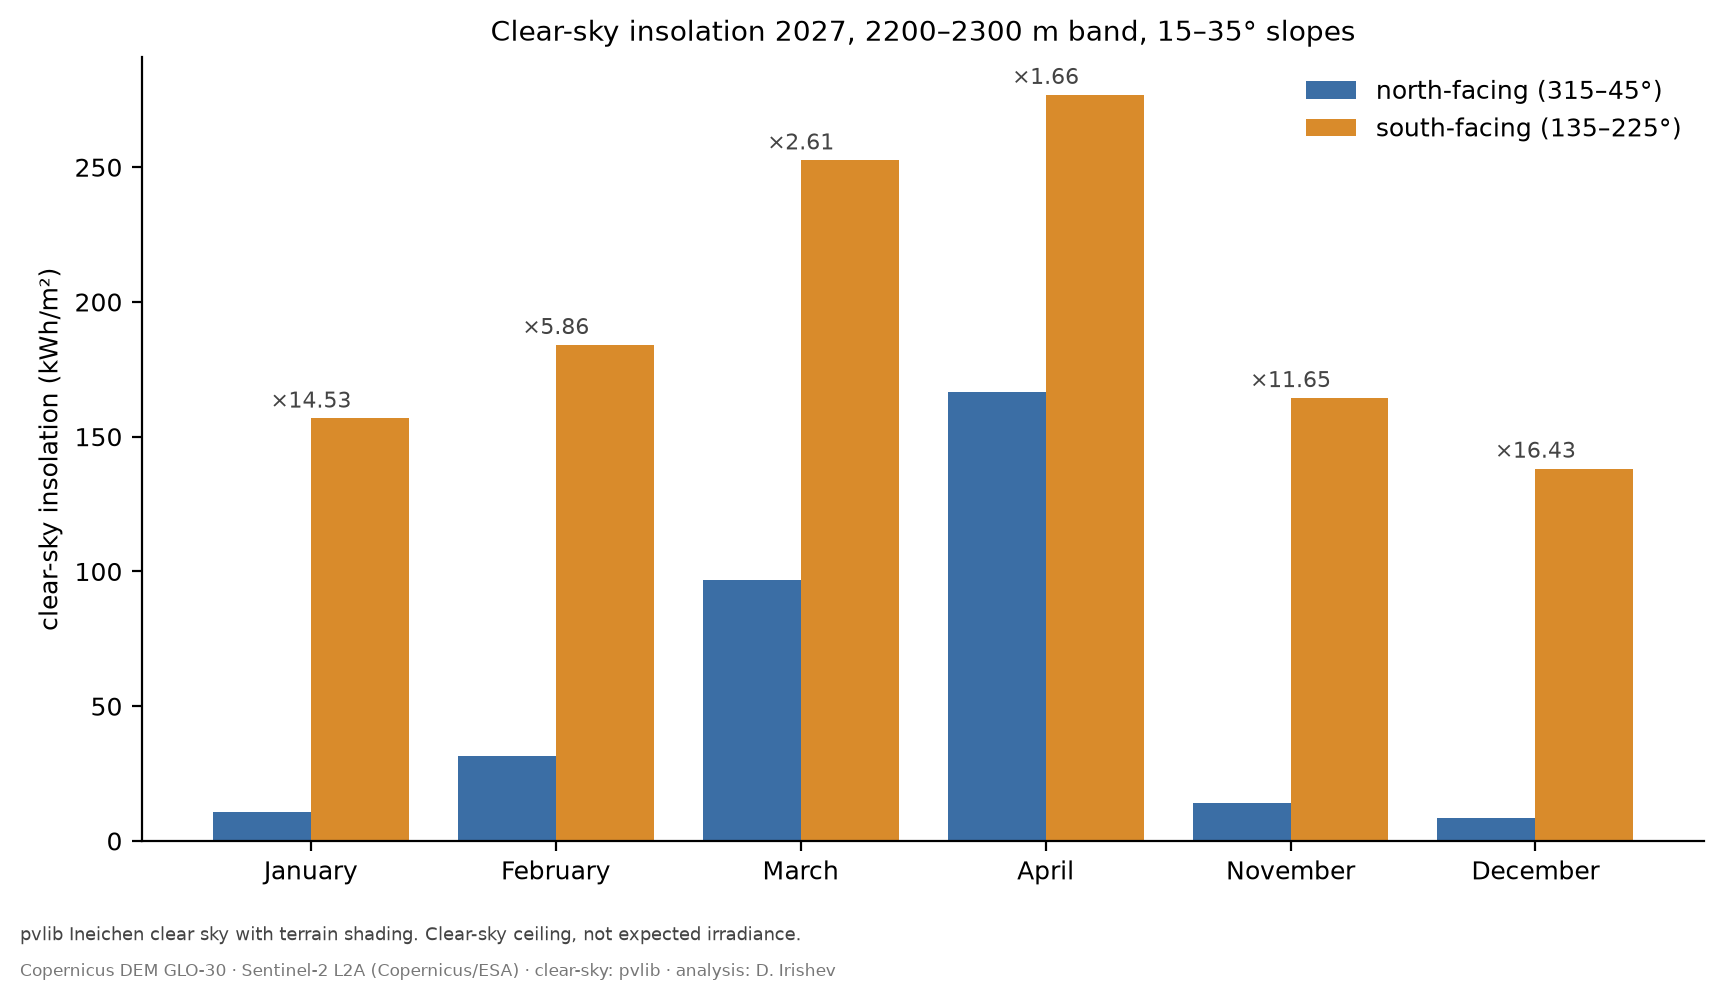

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/03_insolation_2027_north_south.png')

In [9]:
fig, ax = plt.subplots(figsize=(8.6, 4.6))
x = np.arange(len(outlook))
ax.bar(x - 0.2, outlook["median_north_2200_2300"], 0.4, label="north-facing (315–45°)",
       color="#3b6ea5")
ax.bar(x + 0.2, outlook["median_south_2200_2300"], 0.4, label="south-facing (135–225°)",
       color="#d98b2b")
for i, r in outlook.iterrows():
    ax.text(i, max(r.median_south_2200_2300, r.median_north_2200_2300) + 4,
            f"×{r.south_over_north_ratio:g}", ha="center", fontsize=8, color="#444")
ax.set_xticks(x); ax.set_xticklabels(outlook["month_name"])
ax.set_ylabel("clear-sky insolation (kWh/m²)")
ax.set_title(f"Clear-sky insolation 2027, {int(FOCUS_BAND[0])}–{int(FOCUS_BAND[1])} m band, "
             f"15–35° slopes")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
save(fig, "03_insolation_2027_north_south.png",
     "pvlib Ineichen clear sky with terrain shading. Clear-sky ceiling, not expected "
     "irradiance.")

## 4. Spring 2027 — three comparable timing scenarios

There is no forecast of 2027 snow cover here, because nothing in this data supports
one. Instead the four-season spring record is re-cut against three calendar windows
— the historical analogue dates, ten days earlier, and ten days later — and the
three maps are compared **on the pixels observed in all three**. That isolates the
effect of timing from the effect of coverage.

**No probabilities are attached to these scenarios.** Assigning one would require a
calibrated and verified model, which this is not.

In [10]:
scenarios = {
    f"10 days earlier ({SPRING_WINDOW[0]} −10d)": -SPRING_SHIFT_DAYS,
    f"historical analogue ({SPRING_WINDOW[0]}→{SPRING_WINDOW[1]})": 0,
    f"10 days later ({SPRING_WINDOW[1]} +10d)": SPRING_SHIFT_DAYS,
}
scen = {}
for name, shift in scenarios.items():
    sel = select_days(hist, month_day_window=SPRING_WINDOW, shift_days=shift)
    scen[name] = snow_frequency(sel, min_valid=MIN_VALID_OBS,
                                min_seasons=MIN_SEASONS_MULTIYEAR)
    print(f"{name:42s}: {scen[name]['n_dates']:2d} dates, "
          f"coverage {scen[name]['coverage']*100:5.1f}%, "
          f"seasons {len(scen[name]['seasons'])}")

common = np.ones(S2_GRID.shape, dtype=bool)
for r_ in scen.values():
    common &= np.isfinite(r_["frequency"])
common &= ski
print(f"\ncommon mask (observed in all three windows, 15–35° slopes): "
      f"{common.sum()} pixels = {common.sum()*400/1e6:.2f} km², "
      f"{common.sum()/max(ski.sum(),1)*100:.1f}% of skiable terrain")

rows = []
for name, r_ in scen.items():
    f = r_["frequency"][common]
    b = common & (dem >= FOCUS_BAND[0]) & (dem < FOCUS_BAND[1])
    rows.append({
        "scenario": name, "n_dates": r_["n_dates"], "n_seasons": len(r_["seasons"]),
        "coverage_full_grid": round(r_["coverage"], 3),
        "median_freq_common_mask": round(float(np.median(f)), 3),
        "p25": round(float(np.percentile(f, 25)), 3),
        "p75": round(float(np.percentile(f, 75)), 3),
        "area_freq_above_0.8_km2": round(float((f >= 0.8).sum() * 400 / 1e6), 2),
        "median_freq_2200_2300": round(float(np.median(r_["frequency"][b])), 3),
    })
scen_tbl = pd.DataFrame(rows)
scen_tbl.to_csv(OUT_TAB / "spring_2027_scenarios.csv", index=False)
print("\n" + scen_tbl.to_string(index=False))

delta = (scen_tbl["median_freq_common_mask"].max()
         - scen_tbl["median_freq_common_mask"].min())
print(f"\nSensitivity: shifting the window by ±10 days moves the median snow "
      f"frequency on the common mask by {delta:.3f} "
      f"({delta*100:.1f} percentage points) across the full ±10-day range.")

10 days earlier (03-11 −10d)              : 33 dates, coverage  98.1%, seasons 4
historical analogue (03-11→04-20)         : 31 dates, coverage  97.4%, seasons 4
10 days later (04-20 +10d)                : 26 dates, coverage  87.2%, seasons 4

common mask (observed in all three windows, 15–35° slopes): 100962 pixels = 40.38 km², 87.2% of skiable terrain

                         scenario  n_dates  n_seasons  coverage_full_grid  median_freq_common_mask   p25  p75  area_freq_above_0.8_km2  median_freq_2200_2300
     10 days earlier (03-11 −10d)       33          4               0.981                    0.925 0.602  1.0                    25.06                  0.771
historical analogue (03-11→04-20)       31          4               0.974                    0.893 0.500  1.0                    23.13                  0.683
       10 days later (04-20 +10d)       26          4               0.872                    0.742 0.280  1.0                    18.50                  0.500

Sensitivit

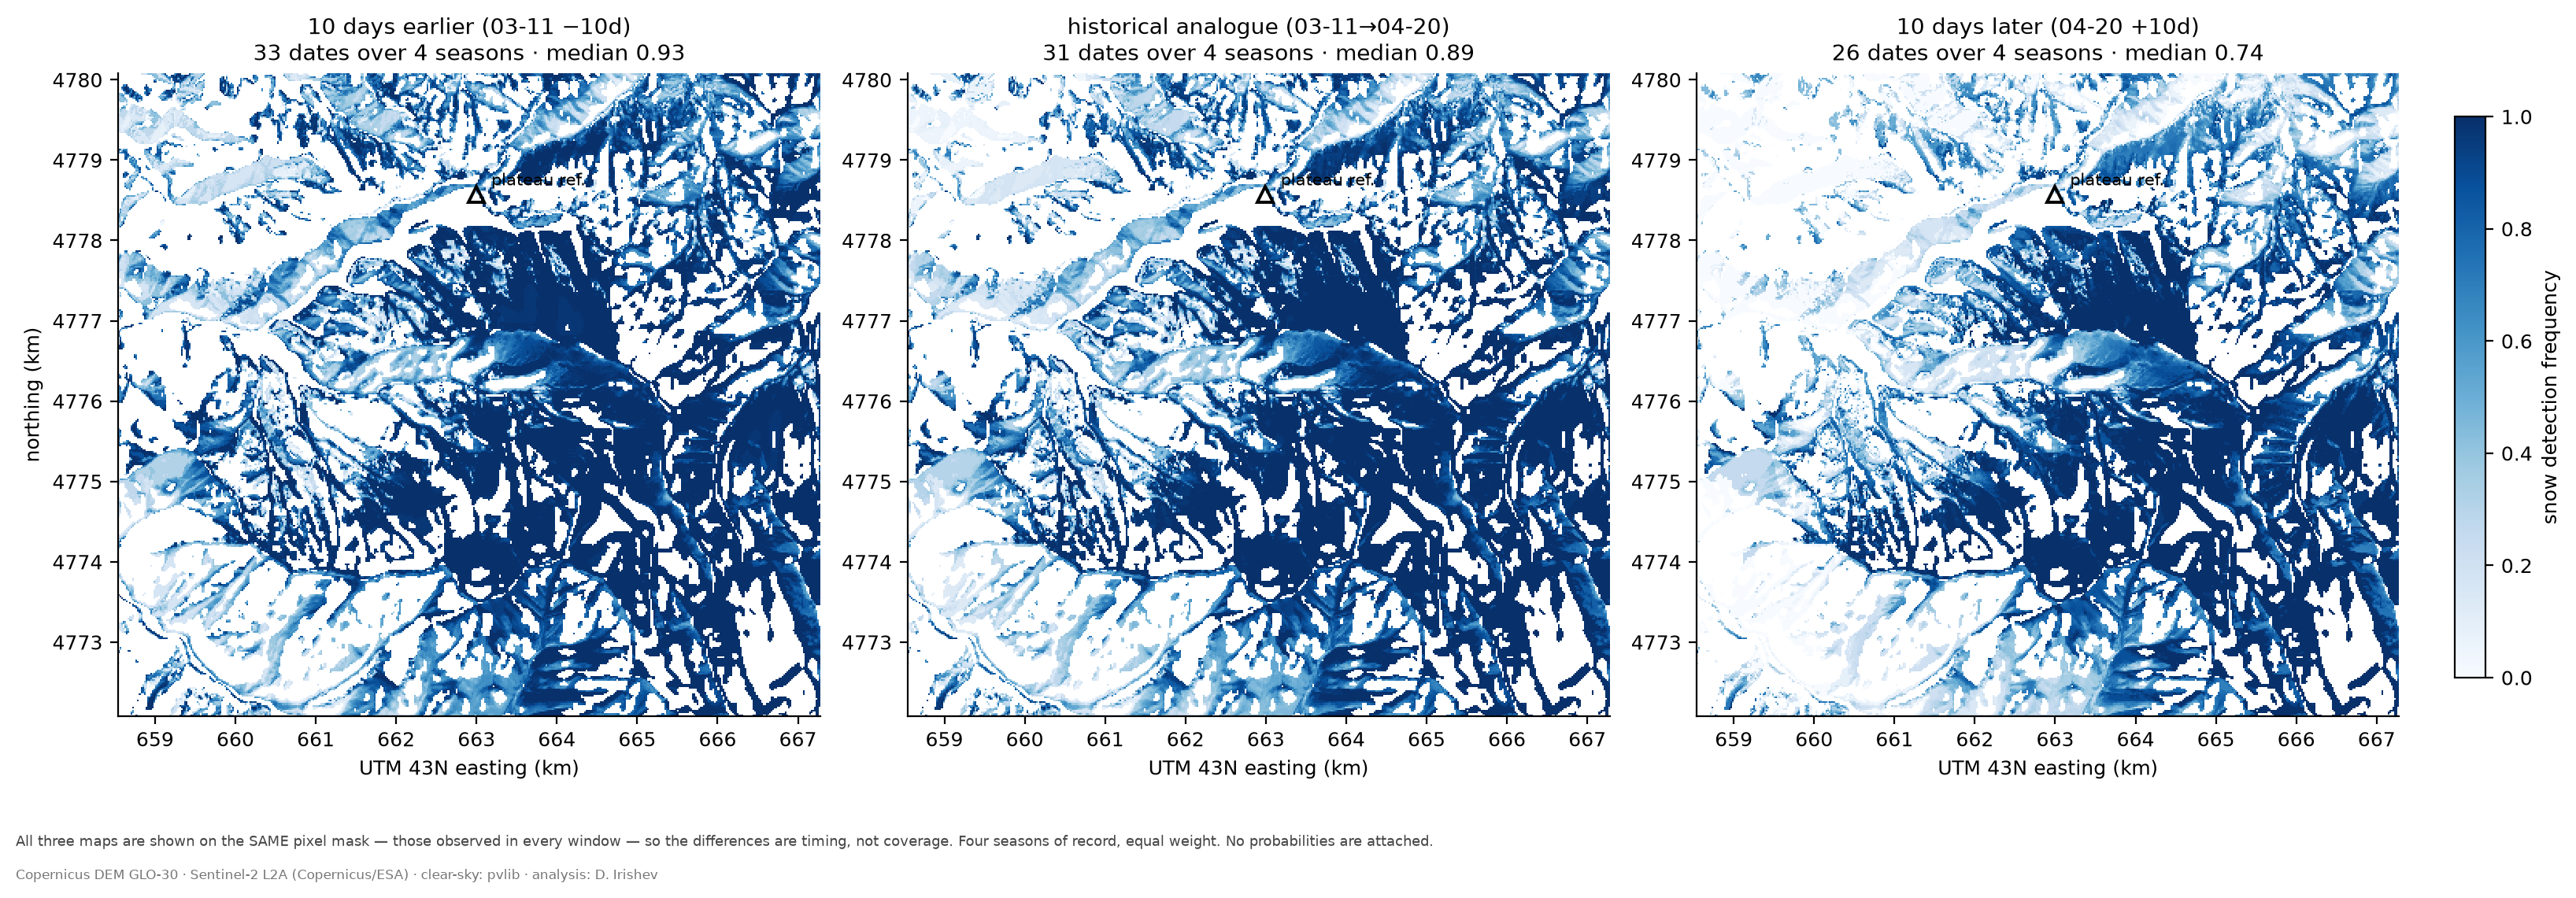

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/03_spring_2027_scenarios.png')

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16.6, 5.4))
for ax, (name, r_) in zip(axes, scen.items()):
    disp = np.where(common, r_["frequency"], np.nan)
    im = map_panel(ax, disp, S2_GRID, "Blues", 0, 1,
                   title=f"{name}\n{r_['n_dates']} dates over {len(r_['seasons'])} seasons · "
                         f"median {np.nanmedian(disp):.2f}",
                   shade=0, cbar=False)
for ax in axes[1:]:
    ax.set_ylabel("")
fig.tight_layout(rect=(0, 0, 0.925, 1))
cax = fig.add_axes([0.938, 0.17, 0.012, 0.66])
fig.colorbar(im, cax=cax).set_label("snow detection frequency", fontsize=9)
save(fig, "03_spring_2027_scenarios.png",
     "All three maps are shown on the SAME pixel mask — those observed in every "
     "window — so the differences are timing, not coverage. Four seasons of record, "
     "equal weight. No probabilities are attached.")

## 5. Published seasonal outlooks, current on the release date

In [12]:
from weather import SEASONAL_OUTLOOKS, write_sources

print(write_sources())
kz = SEASONAL_OUTLOOKS["kazhydromet_winter_2026_27"]
c3s = SEASONAL_OUTLOOKS["c3s_november_2026"]
print(f"\n{kz['issuer']}")
print(f"  document : {kz['document']}")
print(f"  issued   : {kz['issued']}   period: {kz['period']}   scale: {kz['spatial_scale']}")
print(f"  status   : {kz['status']}   analogue years: {kz['analogue_years']}")
for m, v in kz["outlook_for_almaty_area"].items():
    print(f"  {m}: T — {v['temperature']}")
    print(f"  {' ' * len(m)}  P — {v['precipitation']}")
print(f"  caveat   : {kz['caveat']}")
print(f"\n{c3s['issuer']}")
print(f"  issued   : {c3s['issued']} (base time {c3s['base_time']})   period: {c3s['period']}")
print(f"  published highlights: {c3s['published_highlights']}")
print(f"  not readable: {c3s['what_we_could_not_read']}")
print(f"  caveat   : {c3s['caveat']}")

/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/docs/seasonal_outlooks.json

RSE Kazhydromet, Hydrometeorological Centre (Ministry of Ecology and Natural Resources, Kazakhstan)
  document : СЕЗОННЫЙ ПРОГНОЗ ПОГОДЫ. Декабрь 2026 года – февраль 2027 года
  issued   : 2026-11-16   period: 2026-12-01 .. 2027-02-28   scale: 17 oblasts of Kazakhstan; no separate mountain-zone forecast
  status   : advisory (консультативный)   analogue years: December 2005; January-February 2026
  december_2026: T — above normal by 1-2 C over most of the country; near normal in the east of Almaty oblast
                 P — near normal across the whole country
  january_2027: T — above normal by 1-2 C over most of the country (Almaty oblast not listed among near-normal areas)
                P — below normal in the northern half of Almaty oblast
  february_2027: T — above normal by 1-3 C over most of the country (Almaty oblast not listed among near-normal areas)
             

### What these outlooks can and cannot settle

Both are warm-leaning for the coming winter at a scale of hundreds of kilometres.
Neither resolves the two kilometres of relief inside one rectangle, and neither
forecasts snow depth. The gap between an oblast-scale temperature anomaly and an operational
answer is exactly the gap local measurement closes.

In [13]:
needs = pd.DataFrame([
    {"question": "snow depth and water equivalent",
     "needed_measurement": "automatic snow pillow or ultrasonic depth sensor plus "
                           "manual density cores, on at least one shaded and one sunny plot",
     "why_satellite_cannot": "optical imagery sees the surface, not the depth below it"},
    {"question": "season opening date",
     "needed_measurement": "continuous depth record against an operating threshold, "
                           "over several seasons",
     "why_satellite_cannot": "a 5-day revisit with cloud gaps cannot resolve a "
                             "threshold crossing to the day"},
    {"question": "snowmaking windows",
     "needed_measurement": "wet-bulb temperature at the gun line, wind speed and "
                           "direction, water source yield and temperature, equipment "
                           "curves, target depth",
     "why_satellite_cannot": "none of these quantities is observed from orbit"},
    {"question": "avalanche terrain classification",
     "needed_measurement": "snowpack profiles, wind transport and loading patterns, "
                           "mapped start and runout zones, local forecaster judgement",
     "why_satellite_cannot": "slope angle is geometry; release depends on the snowpack"},
    {"question": "real (not clear-sky) irradiance",
     "needed_measurement": "pyranometer pair on contrasting aspects",
     "why_satellite_cannot": "the model here is clear-sky by construction; cloud "
                             "attenuation is unmeasured"},
])
needs.to_csv(OUT_TAB / "local_measurements_required.csv", index=False)
print(needs.to_string(index=False))

                        question                                                                                                                 needed_measurement                                                           why_satellite_cannot
 snow depth and water equivalent              automatic snow pillow or ultrasonic depth sensor plus manual density cores, on at least one shaded and one sunny plot                       optical imagery sees the surface, not the depth below it
             season opening date                                                       continuous depth record against an operating threshold, over several seasons a 5-day revisit with cloud gaps cannot resolve a threshold crossing to the day
              snowmaking windows wet-bulb temperature at the gun line, wind speed and direction, water source yield and temperature, equipment curves, target depth                                none of these quantities is observed from orbit
avalanche terrain classifica

## 6. A two-week field pilot

| Days | Work | Output |
|---|---|---|
| 1–2 | Overlay official corridors, boundaries and constraints onto these GIS layers; reconcile CRS, datum and resolution | A single aligned project stack, plus a written list of every mismatch found |
| 3–4 | Pick measurement pairs: within one 100 m elevation band, one shaded and one sunny plot, repeated across three bands | Six staked plots with coordinates and access notes |
| 5–11 | Field week: snow depth and density at every plot, a pyranometer pair on contrasting aspects, timed photographs, handheld GNSS check of the DEM | Measured depths and irradiance against the predicted exposure ranking |
| 12–13 | Re-run notebooks 01–03 with the field data as a check set; quantify where the satellite frequency was right and where it was not | Updated GeoTIFFs and an error table by exposure class |
| 14 | Hand over | GeoTIFFs, tables, notebooks, and a discrepancy log naming each disagreement and its likely cause |

**Next stage, if the pilot holds up:** a drone DEM over the corridors that matter
(sub-metre, which resolves the terrain the 30 m DEM smooths away), local wind
modelling for snow transport and drift loading, and skier-flow modelling once
designed geometry exists.

## 7. Outputs

In [14]:
written = [
    write_geotiff(OUT_TIF / "field_priority_class.tif", prio, S2_GRID, nodata=255,
                  dtype="uint8",
                  description="0=outside 15-35deg, 1=low sun/frequent snow, "
                              "2=high sun/infrequent snow, 3=other skiable, "
                              "4=skiable but insufficient coverage",
                  thresholds=json.dumps(prio_meta)),
    write_geotiff(OUT_TIF / f"slope_above_{int(STEEP_SLOPE_MIN)}deg.tif", steep, S2_GRID,
                  nodata=255, dtype="uint8",
                  description=f"1 = slope > {STEEP_SLOPE_MIN}° (geometry only)"),
    write_geotiff(OUT_TIF / "snow_frequency_spring_window_4season.tif",
                  spring4["frequency"], S2_GRID, nodata=-9999,
                  description="snow detection frequency, spring window, 4 seasons"),
]
for name, r_ in scen.items():
    tag = ("earlier" if "earlier" in name else "later" if "later" in name else "analogue")
    written.append(write_geotiff(
        OUT_TIF / f"spring_2027_scenario_{tag}.tif",
        np.where(common, r_["frequency"], np.nan), S2_GRID, nodata=-9999,
        description=f"spring scenario '{tag}', common mask, 4 seasons equal weight"))
for m in OUTLOOK_MONTHS_2027:
    key = f"{OUTLOOK_YEAR}_{m:02d}"
    written.append(write_geotiff(
        OUT_TIF / f"insolation_2027_{m:02d}_kwh_m2.tif", ins[key]["total"],
        DEM_GRID, nodata=-9999,
        description=f"clear-sky POA insolation, {OUTLOOK_YEAR}-{m:02d}, kWh/m2"))
written.append(write_geotiff(OUT_TIF / "spring_2027_common_mask.tif",
                             common.astype("uint8"), S2_GRID, nodata=255, dtype="uint8",
                             description="1 = observed in all three spring windows "
                                         "and 15-35 deg slope"))

json.dump({
    "run_date": RUN_DATE,
    "focus_band_m": list(FOCUS_BAND),
    "slope_window_deg": [SKIABLE_SLOPE_MIN, SKIABLE_SLOPE_MAX],
    "field_priority": prio_meta, "steep_layer": steep_meta,
    "spring_window": list(SPRING_WINDOW), "spring_shift_days": SPRING_SHIFT_DAYS,
    "spring_scenarios": scen_tbl.to_dict(orient="records"),
    "common_mask_pixels": int(common.sum()),
    "common_mask_km2": round(float(common.sum() * 400 / 1e6), 3),
    "seasonal_outlooks": {k: {"issuer": v["issuer"], "issued": v["issued"],
                              "url": v["url"]} for k, v in SEASONAL_OUTLOOKS.items()},
}, open(OUT_TIF / "planning_metadata.json", "w"), indent=1)

print(f"{len(written)} GeoTIFFs written")
for p in written:
    print(f"  {p.name}")

13 GeoTIFFs written
  field_priority_class.tif
  slope_above_30deg.tif
  snow_frequency_spring_window_4season.tif
  spring_2027_scenario_earlier.tif
  spring_2027_scenario_analogue.tif
  spring_2027_scenario_later.tif
  insolation_2027_01_kwh_m2.tif
  insolation_2027_02_kwh_m2.tif
  insolation_2027_03_kwh_m2.tif
  insolation_2027_04_kwh_m2.tif
  insolation_2027_11_kwh_m2.tif
  insolation_2027_12_kwh_m2.tif
  spring_2027_common_mask.tif
